In [1]:
!nvidia-smi

Sat Jul 20 13:16:48 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.183.01             Driver Version: 535.183.01   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA GeForce GTX 1080        Off | 00000000:17:00.0 Off |                  N/A |
|  0%   27C    P8               7W / 198W |      6MiB /  8192MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [2]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.transforms import ToTensor
from torch.utils.data import Dataset

class ThoughtvizDataset(Dataset):
    def __init__(self, data_dir, num=None, transforms=None):
        self.data_dir = data_dir
        self.transforms = transforms
        self.images = []
        self.labels = []
        
        # Load images and labels
        for root, dirs, files in os.walk(data_dir):
            for file in files:
                if file.endswith(('.png', '.jpg', '.JPEG', '.bmp', '.tiff')):
                    self.images.append(os.path.join(root, file))
                    # Assume the label is the name of the parent directory
                    self.labels.append(os.path.basename(root))
        
        # If num is specified, limit the number of images
        if num is not None:
            self.images = self.images[:num]
            self.labels = self.labels[:num]
        
    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        label = self.labels[idx]
        img = Image.open(img_path).convert('RGB')
        
        if self.transforms:
            img = self.transforms(img)
        
        return img, label

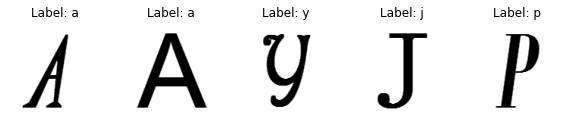

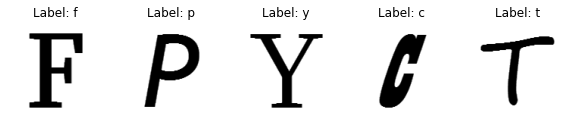

In [12]:
def show_random_images(dataset, num_images):
    plt.figure(figsize=(10, 10))
    for i in range(num_images):
        index = random.randint(0, len(dataset) - 1)
        img, label = dataset[index]
        img = img.permute(1, 2, 0).squeeze().numpy()  # Converti l'immagine in formato numpy

        plt.subplot(1, num_images, i + 1)
        plt.imshow(img, cmap='gray')
        plt.title(f'Label: {label}')
        plt.axis('off')
    plt.show()

# Definizione del dataset THOUGHTVIZ
data_dir_train = '../../thoughtvizdataset/charimages/train/'
thoughtviz_dataset = ThoughtvizDataset(data_dir_train, transforms=ToTensor())
show_random_images(thoughtviz_dataset, num_images=5)

data_dir_test = '../../thoughtvizdataset/charimages/test/'
thoughtviz_dataset = ThoughtvizDataset(data_dir_test, transforms=ToTensor())
show_random_images(thoughtviz_dataset, num_images=5)